<a href="https://colab.research.google.com/github/The-Harsh-07/RCA-CIE-Activity-AD3121/blob/main/Unit-2/RCA_CIE_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc,
)

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
target_names = {0: "malignant (0)", 1: "benign (1)"}

print("Shape (rows, cols):", df.shape)
display(df.head())
print("\nMissing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("Unique target values:", df["target"].unique())

Shape (rows, cols): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Missing values: 0 | Duplicate rows: 0
Unique target values: [0 1]


In [3]:
class_counts = df["target"].value_counts().sort_index()
print("\nClass counts:\n", class_counts.rename(index=target_names))
print("Class proportions:\n", (class_counts / len(df)).rename(index=target_names).round(4))


Class counts:
 target
malignant (0)    212
benign (1)       357
Name: count, dtype: int64
Class proportions:
 target
malignant (0)    0.3726
benign (1)       0.6274
Name: count, dtype: float64


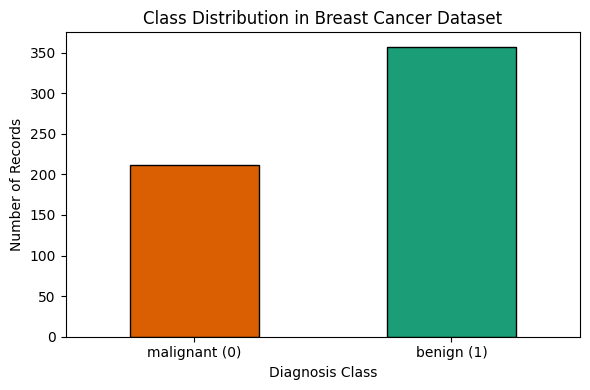

In [4]:
plt.figure(figsize=(6, 4))
class_counts.rename(index=target_names).plot(kind="bar", color=["#d95f02", "#1b9e77"], edgecolor="black")
plt.title("Class Distribution in Breast Cancer Dataset")
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"\nTrain set size: {len(X_train)} | Test set size: {len(X_test)}")
print("Train class counts:\n", y_train.value_counts().sort_index().rename(index=target_names))
print("Test class counts:\n", y_test.value_counts().sort_index().rename(index=target_names))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train set size: 455 | Test set size: 114
Train class counts:
 target
malignant (0)    170
benign (1)       285
Name: count, dtype: int64
Test class counts:
 target
malignant (0)    42
benign (1)       72
Name: count, dtype: int64


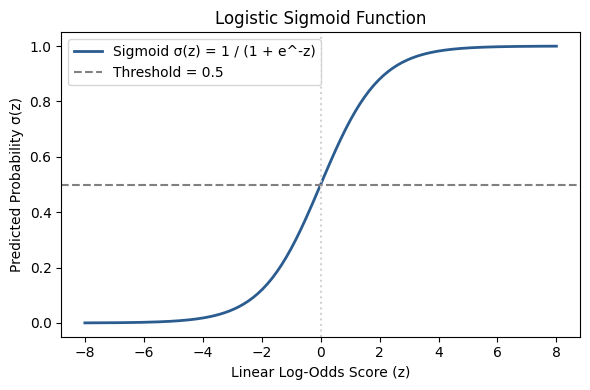

In [6]:
z_vals = np.linspace(-8, 8, 200)
sig_vals = 1 / (1 + np.exp(-z_vals))

plt.figure(figsize=(6, 4))
plt.plot(z_vals, sig_vals, color="#2b5c8f", linewidth=2, label="Sigmoid σ(z) = 1 / (1 + e^-z)")
plt.axhline(0.5, color="gray", linestyle="--", label="Threshold = 0.5")
plt.axvline(0.0, color="lightgray", linestyle=":")
plt.title("Logistic Sigmoid Function")
plt.xlabel("Linear Log-Odds Score (z)")
plt.ylabel("Predicted Probability σ(z)")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_scaled, y_train)

print("\nModel settings:", clf.get_params())
print(f"Intercept (b0): {clf.intercept_[0]:.4f}")

coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": clf.coef_[0],
    "direction_for_benign_1": np.where(clf.coef_[0] > 0, "Increases P(y=1)", "Decreases P(y=1)")
}).sort_values("coefficient", key=abs, ascending=False)
print("\nTop 10 features by |coefficient| (on standardized scale):")
display(coef_df.head(10))


Model settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Intercept (b0): 0.3022

Top 10 features by |coefficient| (on standardized scale):


,feature,coefficient,direction_for_benign_1
21,worst texture,-1.255088,Decreases P(y=1)
10,radius error,-1.082965,Decreases P(y=1)
27,worst concave points,-0.953686,Decreases P(y=1)
23,worst area,-0.947756,Decreases P(y=1)
20,worst radius,-0.947616,Decreases P(y=1)
28,worst symmetry,-0.939181,Decreases P(y=1)
13,area error,-0.929104,Decreases P(y=1)
26,worst concavity,-0.823151,Decreases P(y=1)
22,worst perimeter,-0.763220,Decreases P(y=1)
24,worst smoothness,-0.746625,Decreases P(y=1)


In [8]:
y_test_prob = clf.predict_proba(X_test_scaled)[:, 1]  # Probability of class 1 (benign)
y_test_pred_05 = (y_test_prob >= 0.5).astype(int)

sample_preds = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Actual_Name": [target_names[v] for v in y_test.values],
    "Pred_Prob_Class1": y_test_prob,
    "Pred_Label_0.5": y_test_pred_05,
})
print("\nSample test predictions (first 12 rows):")
display(sample_preds.head(12).round({"Pred_Prob_Class1": 4}))

for t in [0.3, 0.5, 0.7]:
    preds_t = (y_test_prob >= t).astype(int)
    print(f"Threshold {t:.1f} -> Predicted Class 1 count: {preds_t.sum()} / {len(preds_t)} "
          f"| Predicted Class 0 count: {(preds_t == 0).sum()}")


Sample test predictions (first 12 rows):


,Actual_Label,Actual_Name,Pred_Prob_Class1,Pred_Label_0.5
0,0,malignant (0),0.0000,0
1,1,benign (1),1.0000,1
2,0,malignant (0),0.0064,0
3,1,benign (1),0.5335,1
4,0,malignant (0),0.0000,0
5,1,benign (1),0.9922,1
6,1,benign (1),1.0000,1
7,0,malignant (0),0.0000,0
8,0,malignant (0),0.0001,0
9,0,malignant (0),0.0000,0


Threshold 0.3 -> Predicted Class 1 count: 74 / 114 | Predicted Class 0 count: 40
Threshold 0.5 -> Predicted Class 1 count: 72 / 114 | Predicted Class 0 count: 42
Threshold 0.7 -> Predicted Class 1 count: 68 / 114 | Predicted Class 0 count: 46


In [9]:
cm = confusion_matrix(y_test, y_test_pred_05, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0       # Sensitivity / TPR for class 1
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0  # TNR for class 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
roc_auc = roc_auc_score(y_test, y_test_prob)

print(f"\nConfusion Matrix (rows=Actual, cols=Predicted; order [0=malignant, 1=benign]):\n{cm}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


Confusion Matrix (rows=Actual, cols=Predicted; order [0=malignant, 1=benign]):
[[41  1]
 [ 1 71]]
TN=41, FP=1, FN=1, TP=71


In [10]:
metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (class 1)", "Recall / Sensitivity (class 1)", "Specificity (class 0)", "F1-Score (class 1)", "ROC-AUC"],
    "Formula": [
        "(TP + TN) / (TP + TN + FP + FN)",
        "TP / (TP + FP)",
        "TP / (TP + FN)",
        "TN / (TN + FP)",
        "2 * Precision * Recall / (Precision + Recall)",
        "Area under TPR vs FPR curve across thresholds"
    ],
    "Test_Value": [accuracy, precision, recall, specificity, f1, roc_auc]
})
display(metrics_summary.round({"Test_Value": 4}))

print("\nFull Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred_05, target_names=["malignant (0)", "benign (1)"]))

,Metric,Formula,Test_Value
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),0.9825
1,Precision (class 1),TP / (TP + FP),0.9861
2,Recall / Sensitivity (class 1),TP / (TP + FN),0.9861
3,Specificity (class 0),TN / (TN + FP),0.9762
4,F1-Score (class 1),2 * Precision * Recall / (Precision + Recall),0.9861
5,ROC-AUC,Area under TPR vs FPR curve across thresholds,0.9954



Full Classification Report (Test Set):
               precision    recall  f1-score   support

malignant (0)       0.98      0.98      0.98        42
   benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



In [11]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_scaled, y_train)
y_test_dummy = dummy.predict(X_test_scaled)
print(f"Majority-class baseline Test Accuracy: {accuracy_score(y_test, y_test_dummy):.4f} "
      f"(Precision={precision_score(y_test, y_test_dummy, zero_division=0):.4f}, "
      f"Recall={recall_score(y_test, y_test_dummy, zero_division=0):.4f})")

Majority-class baseline Test Accuracy: 0.6316 (Precision=0.6316, Recall=1.0000)


In [12]:
thresh_rows = []
for t in [0.3, 0.5, 0.7]:
    p_t = (y_test_prob >= t).astype(int)
    thresh_rows.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, p_t),
        "Precision": precision_score(y_test, p_t, zero_division=0),
        "Recall": recall_score(y_test, p_t, zero_division=0),
        "F1_Score": f1_score(y_test, p_t, zero_division=0),
    })
print("\nMetrics Across Thresholds:")
display(pd.DataFrame(thresh_rows).round(4))


Metrics Across Thresholds:


,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.3,0.9825,0.9730,1.0000,0.9863
1,0.5,0.9825,0.9861,0.9861,0.9861
2,0.7,0.9474,0.9853,0.9306,0.9571


In [13]:
y_train_prob = clf.predict_proba(X_train_scaled)[:, 1]
y_train_pred = (y_train_prob >= 0.5).astype(int)
print(f"\nTrain Accuracy: {accuracy_score(y_train, y_train_pred):.4f} | Test Accuracy: {accuracy:.4f}")
print(f"Train ROC-AUC:  {roc_auc_score(y_train, y_train_prob):.4f} | Test ROC-AUC:  {roc_auc:.4f}")


Train Accuracy: 0.9890 | Test Accuracy: 0.9825
Train ROC-AUC:  0.9975 | Test ROC-AUC:  0.9954


In [14]:
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_test_prob)
pr_auc = auc(rec_curve, prec_curve)

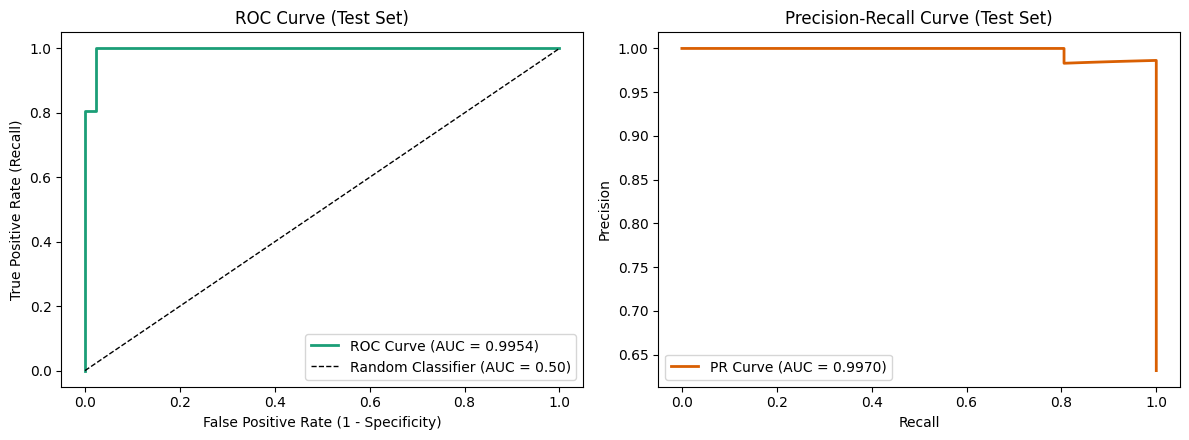

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#1b9e77", lw=2, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier (AUC = 0.50)")
axes[0].set_title("ROC Curve (Test Set)")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend()

axes[1].plot(rec_curve, prec_curve, color="#d95f02", lw=2, label=f"PR Curve (AUC = {pr_auc:.4f})")
axes[1].set_title("Precision-Recall Curve (Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

In [16]:
feat_idx = list(X.columns).index("worst concave points")
x_grid_raw = np.linspace(X["worst concave points"].min(), X["worst concave points"].max(), 200)
X_grid_scaled = np.zeros((len(x_grid_raw), X.shape[1]))
mean_val = X_train["worst concave points"].mean()
std_val = X_train["worst concave points"].std()
X_grid_scaled[:, feat_idx] = (x_grid_raw - mean_val) / std_val
grid_probs = clf.predict_proba(X_grid_scaled)[:, 1]

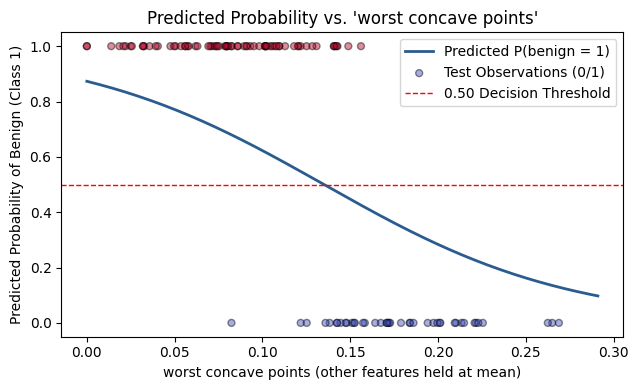

In [17]:
plt.figure(figsize=(6.5, 4))
plt.plot(x_grid_raw, grid_probs, color="#2b5c8f", lw=2, label="Predicted P(benign = 1)")
plt.scatter(X_test["worst concave points"], y_test, alpha=0.45, c=y_test, cmap="coolwarm", edgecolor="k", s=25, label="Test Observations (0/1)")
plt.axhline(0.5, color="red", linestyle="--", lw=1, label="0.50 Decision Threshold")
plt.title("Predicted Probability vs. 'worst concave points'")
plt.xlabel("worst concave points (other features held at mean)")
plt.ylabel("Predicted Probability of Benign (Class 1)")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
new_record = pd.DataFrame([X_train.median().to_dict()])
new_record_scaled = scaler.transform(new_record)
new_prob = clf.predict_proba(new_record_scaled)[0, 1]
new_class = int(new_prob >= 0.5)
print(f"\nNew record predicted P(benign=1): {new_prob:.4f} -> Predicted class: {target_names[new_class]}")


New record predicted P(benign=1): 0.9513 -> Predicted class: benign (1)
